<a href="https://colab.research.google.com/github/wujh03/MSSP6070/blob/main/WeeklyModules/Week09/week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
import requests

category = input("Enter a photo category: ")

Enter a photo category: Tennis


In [5]:
folder = "/content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages"

os.makedirs(folder, exist_ok=True)

print("Folder created:", folder)

Folder created: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages


In [6]:
url = "https://commons.wikimedia.org/w/api.php"

params = {
    "action": "query",
    "generator": "search",
    "gsrsearch": category,
    "gsrnamespace": 6,
    "gsrlimit": 10,
    "prop": "imageinfo",
    "iiprop": "url",
    "format": "json"
}

headers = {
    "User-Agent": "MSSP607ImageDownloader/1.0 (wujh04@gmail.com)"
}

response = requests.get(url, params=params, headers=headers)
response.raise_for_status()

data = response.json()

print("Search completed!")

Search completed!


In [7]:
pages = data["query"]["pages"]

print("Number of results:", len(pages))

for page in pages.values():
    if "imageinfo" in page:
        image_url = page["imageinfo"][0]["url"]
        print(image_url)

Number of results: 10
https://upload.wikimedia.org/wikipedia/commons/9/94/2013_Australian_Open_-_Guillaume_Rufin.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=original
https://upload.wikimedia.org/wikipedia/commons/b/b6/2017_US_Open_Tennis_-_Qualifying_Rounds_-_Viktoriya_Tomova_%28BUL%29_def._Polona_Hercog_%28SLO%29_%2836916572131%29.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=original
https://upload.wikimedia.org/wikipedia/commons/1/17/AEC_Indoor_Tennis_Courts.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=original
https://upload.wikimedia.org/wikipedia/commons/8/8e/AEC_Outdoor_Tennis_Courts.png?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=original
https://upload.wikimedia.org/wikipedia/commons/8/84/Anastasiya_Yakimova%2C_Damen-Tennis-Bundesliga_Moers.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=original
https://upload.wikimedia.org/wikipedia/commons/3/31/An

In [8]:
count = 0

for page in pages.values():

    if "imageinfo" in page:
        image_url = page["imageinfo"][0]["url"]

        name = page["title"].lower()

        if name.endswith((".jpg", ".jpeg")):
            extension = ".jpg"
        elif name.endswith(".png"):
            extension = ".png"
        else:
            continue

        try:
            res = requests.get(image_url, headers=headers, stream=True, timeout=30)
            res.raise_for_status()

            filename = os.path.join(folder, "image_" + str(count + 1) + extension)

            with open(filename, "wb") as file:
                for chunk in res.iter_content(100000):
                    if chunk:
                        file.write(chunk)

            count += 1
            print("Downloaded:", filename)

        except requests.RequestException as error:
            print("Download failed:", error)

        finally:
            if "res" in locals():
                res.close()

print("Total downloaded:", count)

Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_1.jpg
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_2.jpg
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_3.jpg
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_4.png
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_5.jpg
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_6.jpg
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_7.jpg
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_8.jpg
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_9.jpg
Downloaded: /content/drive/MyDrive/MSSP607/Modules/Week09/DownloadedImages/image_10.jpg
Total downloaded: 10


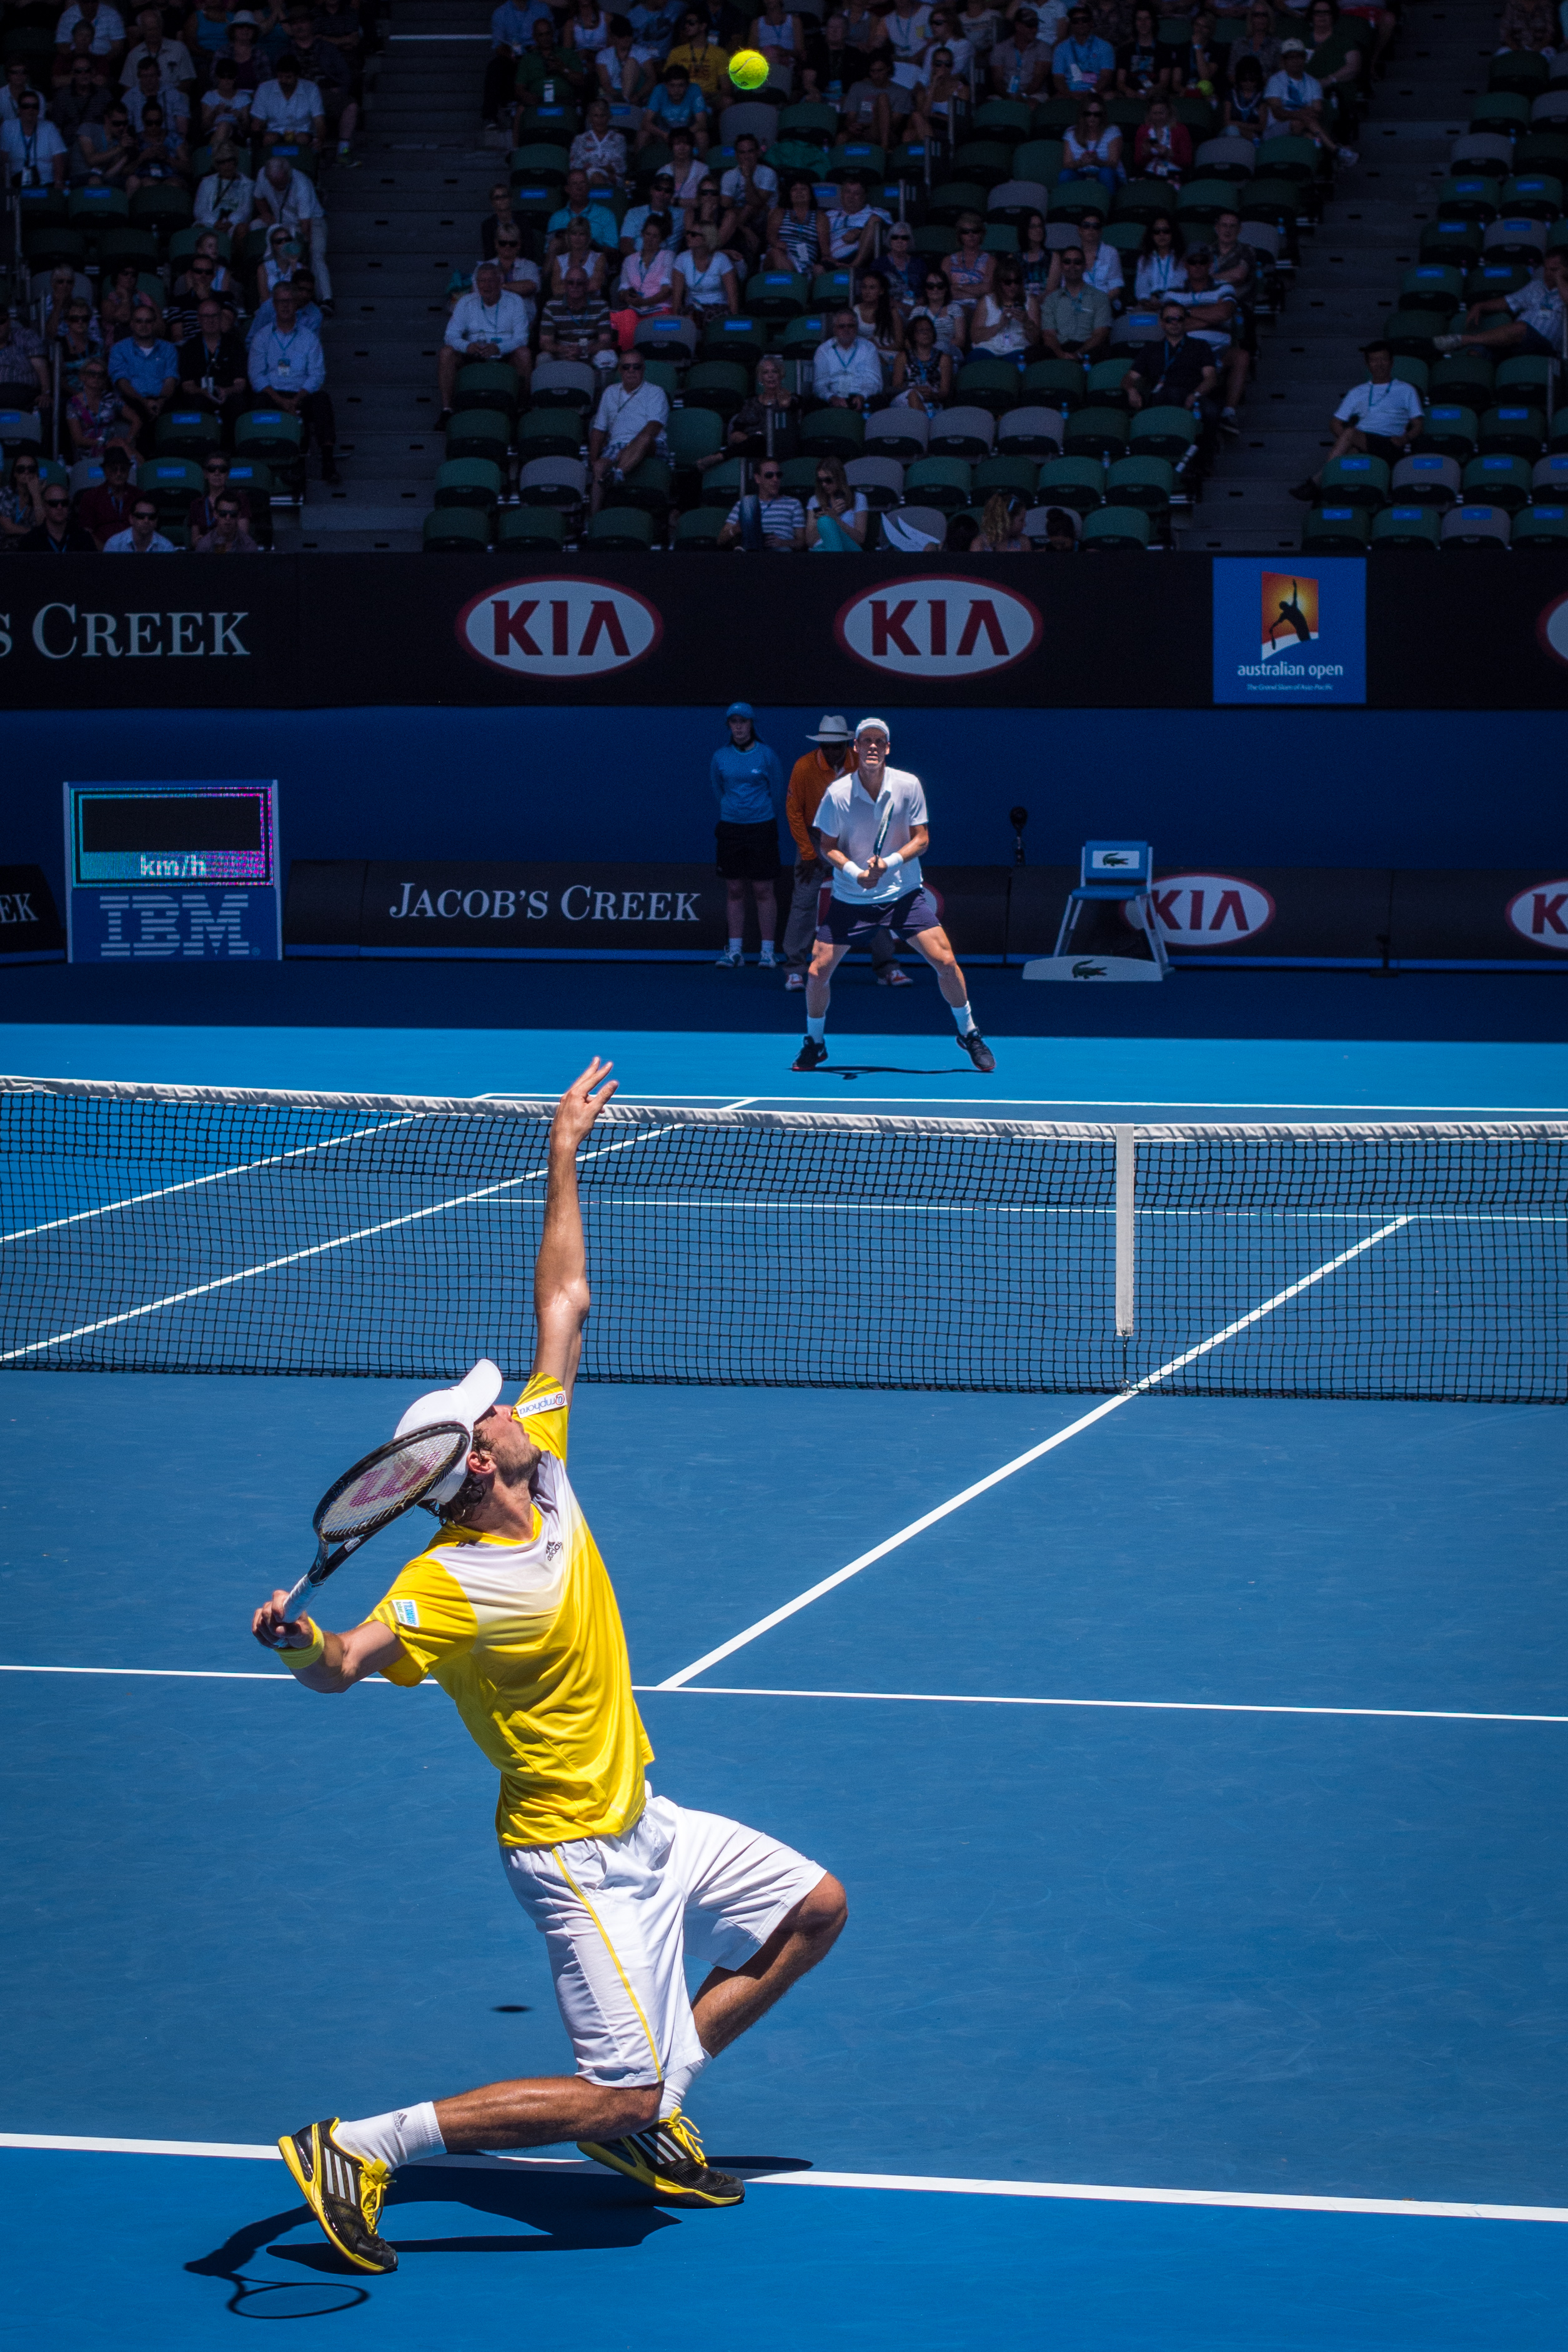

In [9]:
from IPython.display import Image, display

display(Image(filename=os.path.join(folder, "image_1.jpg")))